| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../8_PDE/8_1_PDE_fundamentales.ipynb) | [⏩](../9_METODOS_NUMERICOS_PARA_PDE/9_2_Finite_Element_Method.ipynb) |

# 9.1 Finite Difference Method: discretizar derivadas con stencils

Las diferencias finitas reemplazan derivadas por combinaciones locales de valores en nodos. Su sencillez permite estudiar consistencia, estabilidad y condiciones de frontera con claridad. Construiremos Poisson 1D y 2D, calor explícito y Crank–Nicolson, y advección upwind.

Objetivos: derivar el laplaciano, ensamblar matrices dispersas, medir orden espacial dos, verificar la restricción difusiva del paso y distinguir difusión y dispersión numéricas.

Este cuaderno se ejecuta de arriba abajo y genera todos los datos localmente. Los ejemplos son unidimensionales salvo un experimento 2D pequeño. Se necesitan cálculo multivariable, ecuaciones diferenciales y álgebra lineal. La sencillez de la geometría permite concentrarse en formulación, error, estabilidad y propiedades físicas.

## 1. Malla y derivadas aproximadas

En nodos $x_i=ih$, Taylor produce
$$u_x(x_i)\approx\frac{u_{i+1}-u_{i-1}}{2h},\qquad
u_{xx}(x_i)\approx\frac{u_{i-1}-2u_i+u_{i+1}}{h^2}.$$
Ambas tienen error $O(h^2)$ para suficiente regularidad. Un **stencil** indica qué nodos participan; el laplaciano 1D usa tres. Valores de frontera no son incógnitas interiores cuando se imponen por Dirichlet.

En malla no uniforme estos mismos pesos no son correctos. Para $h_-=x_i-x_{i-1}$ y $h_+=x_{i+1}-x_i$, los pesos deben derivarse usando las distancias reales. Refinar de forma adaptativa exige cambiar tanto geometría como operadores.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.linalg import spsolve
from scipy.optimize import minimize_scalar
plt.rcParams.update({"figure.figsize":(9,4),"axes.grid":True,"font.size":11})
np.set_printoptions(precision=6,suppress=True)

## 2. Poisson 1D y matriz tridiagonal

Para $-u''=f$, $u(0)=a$, $u(1)=b$, los nodos interiores cumplen
$$\frac{-u_{i-1}+2u_i-u_{i+1}}{h^2}=f_i.$$
La matriz tiene diagonal $2/h^2$ y diagonales vecinas $-1/h^2$. Los valores conocidos de frontera se trasladan al lado derecho: $f_1\gets f_1+a/h^2$ y $f_{N-1}\gets f_{N-1}+b/h^2$.

Resolver con `spsolve` evita construir una inversa explícita. La matriz es simétrica definida positiva para este problema Dirichlet y contiene solo $O(N)$ entradas no nulas.

Nodos interiores: 29 no ceros: 85


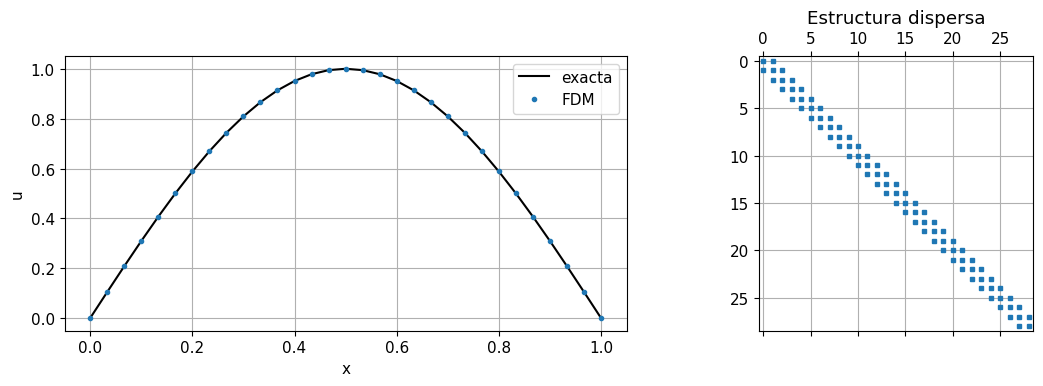

In [2]:
def poisson1d(n,source,left=0.,right=0.):
    x=np.linspace(0,1,n+1); h=1/n
    A=sparse.diags([-np.ones(n-2),2*np.ones(n-1),-np.ones(n-2)],[-1,0,1],format="csr")/h**2
    rhs=np.asarray(source(x[1:-1]),dtype=float).copy()
    rhs[0]+=left/h**2; rhs[-1]+=right/h**2
    u=np.empty(n+1); u[0]=left; u[-1]=right; u[1:-1]=spsolve(A,rhs)
    return x,u,A,rhs

x,u,A,rhs=poisson1d(30,lambda z:np.pi**2*np.sin(np.pi*z))
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(x,np.sin(np.pi*x),"k",label="exacta")
ax[0].plot(x,u,"o",markersize=3,label="FDM"); ax[0].legend()
ax[0].set(xlabel="x",ylabel="u"); ax[1].spy(A,markersize=3)
ax[1].set(title="Estructura dispersa"); plt.tight_layout(); plt.show()
print("Nodos interiores:",A.shape[0],"no ceros:",A.nnz)

**Interpretación del experimento.** La gráfica del patrón muestra localidad: cada ecuación conecta solo vecinos. El error espacial queda aunque el sistema algebraico se resuelva muy bien. La densidad de no ceros decrece al ampliar N.

## 3. Convergencia espacial

La solución fabricada $u_* =\sin(\pi x)$ requiere $f=\pi^2\sin(\pi x)$. Al refinar, medimos norma máxima en nodos y una norma $L^2$ discreta. Para una solución suave y frontera bien implementada se espera segundo orden.

N=10, error max=8.265e-03
N=20, error max=2.059e-03
N=40, error max=5.142e-04
N=80, error max=1.285e-04
N=160, error max=3.213e-05
Órdenes: [2.005349 2.001335 2.000334 2.000083]


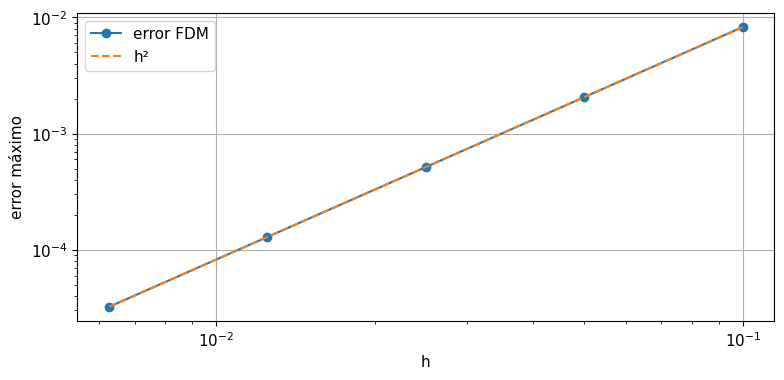

In [3]:
ns=np.array([10,20,40,80,160]); errors=[]
for n in ns:
    x,u,_,_=poisson1d(n,lambda z:np.pi**2*np.sin(np.pi*z))
    error=np.max(abs(u-np.sin(np.pi*x))); errors.append(error)
    print(f"N={n}, error max={error:.3e}")
errors=np.array(errors)
print("Órdenes:",np.log2(errors[:-1]/errors[1:]))
plt.loglog(1/ns,errors,"o-",label="error FDM")
plt.loglog(1/ns,errors[-1]*(ns[-1]/ns)**2,"--",label="h²")
plt.xlabel("h"); plt.ylabel("error máximo"); plt.legend(); plt.show()

**Interpretación del experimento.** Las tasas cercanas a dos prueban este caso suave. En esquinas, fuentes discontinuas o cierres de frontera de menor orden, la tasa global puede cambiar. La norma máxima puede ser más exigente que una media cuadrática.

## 4. Calor explícito y restricción difusiva

Euler temporal más laplaciano central da
$$u_i^{n+1}=u_i^n+r(u_{i-1}^n-2u_i^n+u_{i+1}^n),\quad r=\alpha\Delta t/h^2.$$
Para $0\le r\le1/2$, la actualización es una combinación convexa con pesos $r,1-2r,r$. Esto respeta cotas locales y lleva a la condición de estabilidad 1D. Refinar espacio por dos obliga a reducir el paso por cuatro.

El error combinado típico es $O(\Delta t+h^2)$ para soluciones suaves. Debemos refinar tiempo y espacio de forma controlada para identificar ambos.

r real: 0.3999999999999999 error final: 0.00011674077118106752


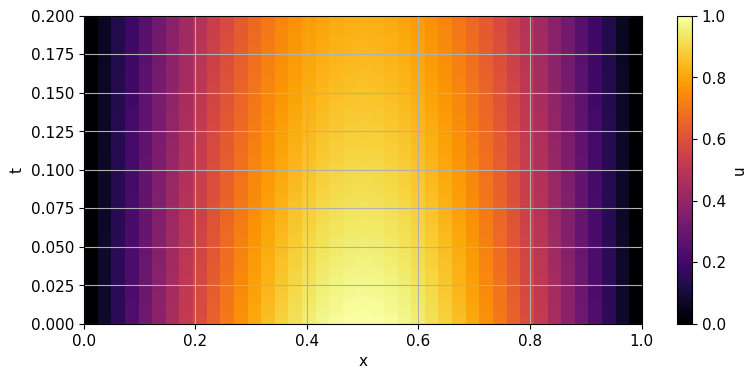

In [4]:
def heat_explicit(n,T,alpha,r_target=0.4,perturb=False):
    x=np.linspace(0,1,n+1); dx=1/n
    steps=int(np.ceil(T/(r_target*dx*dx/alpha)))
    dt=T/steps; r=alpha*dt/dx**2; u=np.sin(np.pi*x)
    if perturb: u[1:-1]+=1e-7*(-1.)**np.arange(1,n)
    history=[u.copy()]; times=[0.]
    for j in range(steps):
        new=u.copy(); new[1:-1]=u[1:-1]+r*(u[:-2]-2*u[1:-1]+u[2:])
        new[0]=new[-1]=0.; u=new
        if (j+1)%max(1,steps//50)==0 or j+1==steps:
            history.append(u.copy()); times.append((j+1)*dt)
    return x,u,np.array(times),np.array(history),r

x,u,times,U,r=heat_explicit(40,0.2,0.1)
plt.imshow(U,origin="lower",aspect="auto",extent=[0,1,0,0.2],cmap="inferno")
plt.xlabel("x"); plt.ylabel("t"); plt.colorbar(label="u"); plt.show()
print("r real:",r,"error final:",np.max(abs(u-np.exp(-0.1*np.pi**2*0.2)*np.sin(np.pi*x))))

**Interpretación del experimento.** La solución difunde de manera estable. La imagen representa instantáneas casi uniformes en tiempo; los números exactos de esas instantáneas están en `times`. En un experimento cuantitativo usa esos tiempos para calcular comparaciones.

## 5. Un paso inestable amplifica ruido de alta frecuencia

Un modo espacial oscilatorio alternante tiene amplificación aproximada $1-4r$. Si $r>1/2$, su módulo supera uno. Una condición inicial suave puede tardar en mostrarlo porque ese modo comienza casi ausente; el redondeo o una perturbación pequeña termina excitándolo.

Añadimos ruido alternante de amplitud $10^{-7}$ para demostrar explícitamente la propagación del modo inestable, sin esperar a que el redondeo lo produzca accidentalmente.

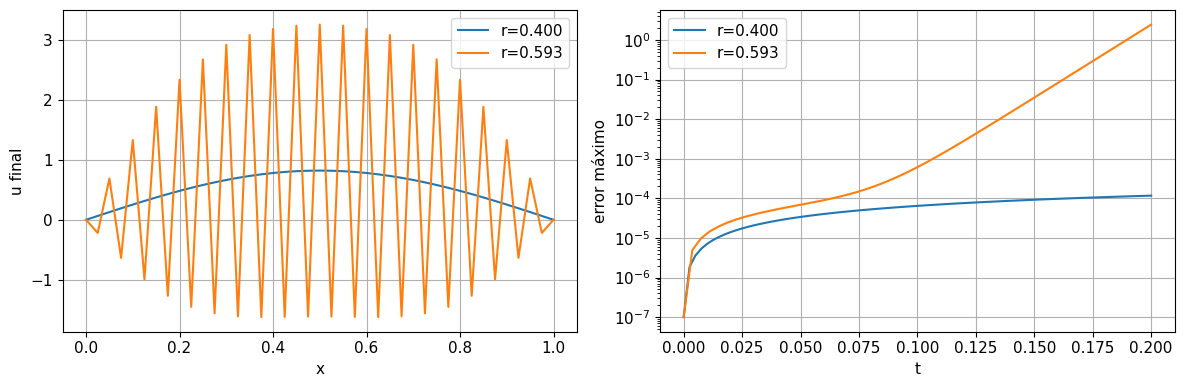

In [5]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
for r_goal in [0.4,0.6]:
    x,u,times,U,r=heat_explicit(40,0.2,0.1,r_goal,perturb=True)
    ax[0].plot(x,u,label=f"r={r:.3f}")
    deviation=np.max(abs(U-np.exp(-0.1*np.pi**2*times[:,None])*np.sin(np.pi*x)[None,:]),axis=1)
    ax[1].semilogy(times,np.maximum(deviation,1e-16),label=f"r={r:.3f}")
for a in ax: a.legend()
ax[0].set(xlabel="x",ylabel="u final"); ax[1].set(xlabel="t",ylabel="error máximo")
plt.tight_layout(); plt.show()

**Interpretación del experimento.** El caso $r\approx0.6$ amplifica el modo de malla y puede mostrar un crecimiento enorme pese a la pequeña perturbación inicial. La condición estable evita ese mecanismo y deja un error de discretización suave.

## 6. Crank–Nicolson: estabilidad sin ese límite

Para el sistema semidiscreto $u'=L_hu$, trapecio implícito produce
$$\left(I-\frac{\Delta t}{2}L_h\right)u^{n+1}
=\left(I+\frac{\Delta t}{2}L_h\right)u^n.$$
Con Laplaciano negativo es estable para cualquier $\Delta t$ en el sentido lineal, pero puede oscilar en modos rígidos con pasos muy grandes. Su error típico es $O(\Delta t^2+h^2)$. Utilizar una factorización reutilizable aprovecha que la matriz permanece fija.

r: 4.0 error: 0.00013958647449840988


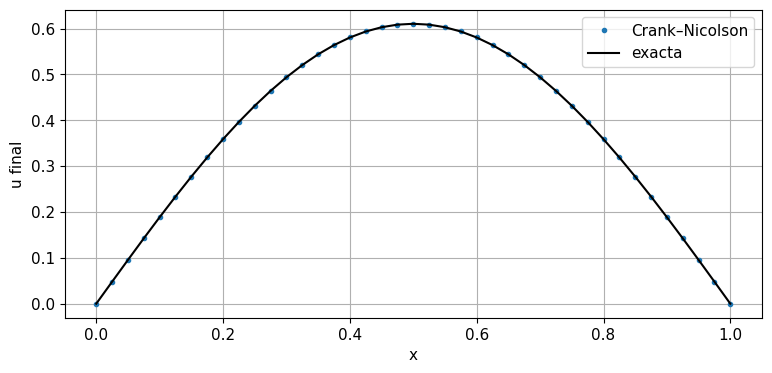

In [6]:
from scipy.sparse.linalg import factorized
n=40; dx=1/n; x=np.linspace(0,1,n+1); alpha=0.1; T=0.5; steps=20; dt=T/steps
Lh=alpha*sparse.diags([np.ones(n-2),-2*np.ones(n-1),np.ones(n-2)],[-1,0,1],format="csc")/dx**2
I=sparse.eye(n-1,format="csc")
solve=factorized(I-dt*Lh/2); B=I+dt*Lh/2
interior=np.sin(np.pi*x[1:-1])
for _ in range(steps): interior=solve(B@interior)
u=np.zeros(n+1); u[1:-1]=interior
plt.plot(x,u,"o",markersize=3,label="Crank–Nicolson")
plt.plot(x,np.exp(-alpha*np.pi**2*T)*np.sin(np.pi*x),"k",label="exacta")
plt.xlabel("x"); plt.ylabel("u final"); plt.legend(); plt.show()
print("r:",alpha*dt/dx**2,"error:",np.max(abs(u-np.exp(-alpha*np.pi**2*T)*np.sin(np.pi*x))))

**Interpretación del experimento.** El valor de r supera el límite explícito pero el resultado sigue estable. La estabilidad amplia permite elegir tiempo por precisión; no garantiza que un paso arbitrariamente grande represente correctamente la evolución.

## 7. Advección upwind y CFL

Para $u_t+c u_x=0$ con $c>0$,
$$u_i^{n+1}=u_i^n-C(u_i^n-u_{i-1}^n),\quad C=c\Delta t/h.$$
El stencil mira hacia el lado de entrada de información. Para $0\le C\le1$ es combinación convexa. En un dominio periódico usamos índices circulares. El método tiene error de primer orden y difusión numérica, aproximadamente proporcional a $ch(1-C)/2$.

El esquema FTCS con diferencia central espacial para advección tiene amplificación de módulo mayor que uno para modos no triviales: no basta copiar el stencil del calor en una PDE distinta.

Masa inicial/final: 0.06327827987523532 0.06327827987523532


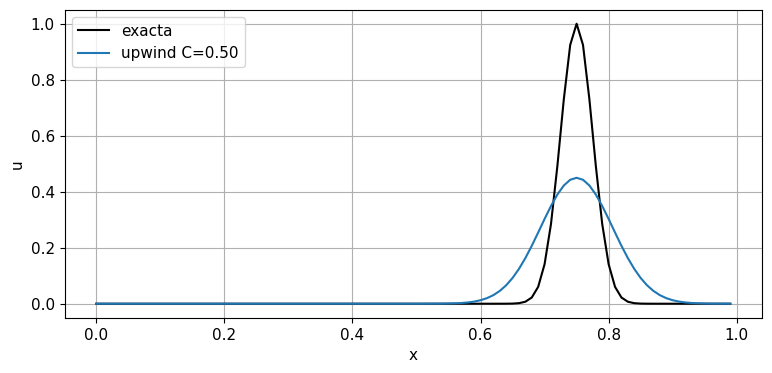

In [7]:
n=100; x=np.arange(n)/n; c_speed=1.; T=0.5; steps=100; dt=T/steps; C=c_speed*dt*n
initial=lambda z:np.exp(-80*np.sin(np.pi*(z-0.25))**2)
u=initial(x)
for _ in range(steps): u=u-C*(u-np.roll(u,1))
plt.plot(x,initial((x-c_speed*T)%1),"k",label="exacta")
plt.plot(x,u,label=f"upwind C={C:.2f}")
plt.xlabel("x"); plt.ylabel("u"); plt.legend(); plt.show()
print("Masa inicial/final:",initial(x).mean(),u.mean())

**Interpretación del experimento.** El perfil se ensancha y pierde altura por difusión numérica mientras conserva la suma periódica. Preservar masa no implica preservar la forma. Con $C=1$, este esquema realiza una traslación exacta de un nodo por paso para datos discretos.

## 8. Poisson 2D y producto de Kronecker

En una malla cuadrada,
$$-\Delta u_{ij}\approx\frac{4u_{ij}-u_{i-1,j}-u_{i+1,j}-u_{i,j-1}-u_{i,j+1}}{h^2}.$$
El stencil tiene cinco puntos. Con fronteras cero, la matriz se construye como $A=I\otimes T+T\otimes I$, donde $T$ es el operador 1D. Una solución fabricada es $u=\sin(\pi x)\sin(\pi y)$ con fuente $2\pi^2u$.

El orden de aplanado de arreglos debe coincidir con la definición del producto de Kronecker; una matriz con dimensiones correctas puede conectar nodos incorrectos si se mezclan convenciones.

Desconocidas: 841 nnz: 4089 error: 0.000914353553069569


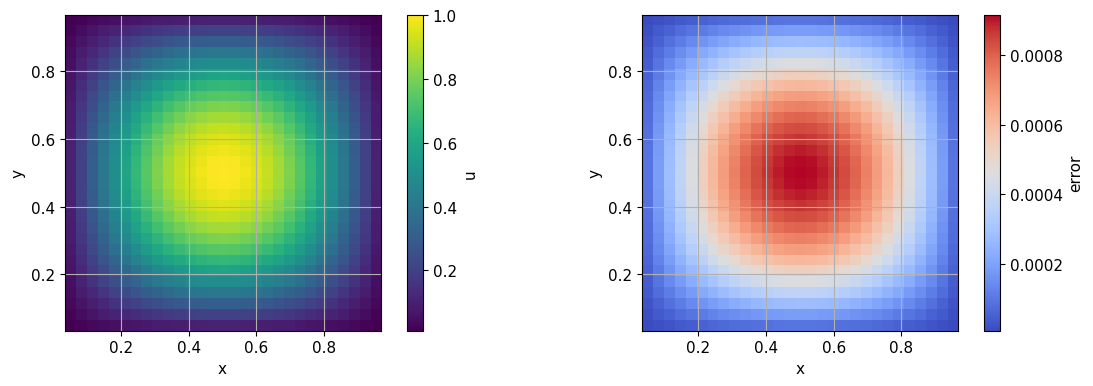

In [8]:
n=30; interior_nodes=n-1; dx=1/n
q=np.arange(1,n)*dx; X,Y=np.meshgrid(q,q,indexing="ij")
T1=sparse.diags([-np.ones(n-2),2*np.ones(n-1),-np.ones(n-2)],[-1,0,1],format="csr")/dx**2
I=sparse.eye(interior_nodes,format="csr")
A2=sparse.kron(I,T1)+sparse.kron(T1,I)
exact=np.sin(np.pi*X)*np.sin(np.pi*Y)
U=spsolve(A2,2*np.pi**2*exact.ravel()).reshape(exact.shape)
fig,ax=plt.subplots(1,2,figsize=(12,4))
im=ax[0].imshow(U.T,origin="lower",extent=[dx,1-dx,dx,1-dx],cmap="viridis")
fig.colorbar(im,ax=ax[0],label="u")
im=ax[1].imshow((U-exact).T,origin="lower",extent=[dx,1-dx,dx,1-dx],cmap="coolwarm")
fig.colorbar(im,ax=ax[1],label="error")
for a in ax: a.set(xlabel="x",ylabel="y")
plt.tight_layout(); plt.show()
print("Desconocidas:",A2.shape[0],"nnz:",A2.nnz,"error:",np.max(abs(U-exact)))

**Interpretación del experimento.** La solución discreta y el error siguen la forma del modo. La matriz dispersa evita almacenar todas las conexiones nulas. No visualizamos valores de frontera aquí: las imágenes muestran únicamente nodos interiores.

## 9. Fronteras y nodos fantasma

Para Neumann puede introducirse un nodo fantasma y derivar una relación que imponga la pendiente, o emplear una fórmula unilateral. La elección afecta orden y simetría del sistema. Para Dirichlet no nulo se deben incluir contribuciones en el lado derecho, como en `poisson1d`.

Una prueba útil es $u(x)=1+2x$, fuente cero y fronteras $1,3$: el método central debe reproducir la recta salvo redondeo. Fronteras periódicas requieren conectar primer y último nodo y no duplicar el extremo. Neumann homogéneo para calor puede conservar masa, pero solo si la discretización del flujo es compatible con ese balance.

## 10. Método de líneas y refinamiento conjunto

Tras discretizar espacio queda un sistema ODE $\dot U=F_h(U)$. Podemos integrarlo con métodos del capítulo anterior. Los autovalores del laplaciano crecen en magnitud como $h^{-2}$, creando rigidez al refinar.

Para separar errores usa primero un tiempo muy preciso y refina espacio, y después espacio muy fino y refina tiempo. Si refinas ambos sin saber sus órdenes, el error dominante puede ocultar al otro. Para una meta de precisión, balancear $\Delta t^p$ y $h^q$ evita gastar trabajo en un componente ya mucho más preciso.

## 11. Propiedades y limitaciones

FDM es eficiente en geometrías estructuradas y permite stencils fáciles de vectorizar. En fronteras complejas, mallas curvilíneas o discontinuidades de coeficientes, la implementación exige más cuidado. Para una difusión $\partial_x(a(x)u_x)$ con $a$ variable, discretiza la divergencia de un flujo y define coeficientes en interfaces; usar $a_i u_{xx}$ omite el término $a_xu_x$.

Compara residual, error y balance. Un esquema conservativo puede perder precisión de picos; un esquema de alto orden puede oscilar cerca de discontinuidades. No hay una propiedad única que sustituya el conjunto de requisitos del modelo.

## 12. Verificación, validación y vínculo con SciML

Una **verificación** pregunta si resolvemos correctamente las ecuaciones que elegimos: compara soluciones exactas, realiza refinamiento de malla, mide residual y observa propiedades discretas. Una **validación física** compara el modelo con mediciones independientes y sus incertidumbres. Un método de diferencias finitas puede estar perfectamente verificado y aun así representar una ley física inadecuada.

Para fabricar una solución conocida, elige $u_*$, sustitúyela en la PDE y deriva la fuente y las fronteras correspondientes. Al ejecutar el solver, compara con $u_*$ en una norma definida. Este método detecta signos, índices y condiciones de frontera mal implementados; no prueba por sí solo desempeño en todo problema.

Si los campos numéricos se usan para entrenar un operador neuronal, documenta malla, paso temporal, condiciones de frontera, precisión del solver y distribución de parámetros. Reserva casos de prueba y compara también resoluciones no vistas. Un modelo aprendido puede reproducir el sesgo de discretización de sus etiquetas; una métrica sobre la misma malla no revela necesariamente ese problema.

Una PINN utiliza residuales de una PDE, pero también necesita satisfacer datos iniciales y de frontera. Un residual pequeño en pocos puntos no garantiza un campo preciso entre ellos. Compara contra una solución numérica refinada, revisa balances y calcula una norma sobre una malla de evaluación independiente. Las distintas formulaciones de residual, fuerte e integral, aportan criterios científicos diferentes.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../8_PDE/8_1_PDE_fundamentales.ipynb) | [⏩](../9_METODOS_NUMERICOS_PARA_PDE/9_2_Finite_Element_Method.ipynb) |